# Detección y análisis de grietas en hormigón: CNN + Grad-CAM + segmentación + informe

Este notebook entrena **una CNN personalizada (Keras)** para clasificar superficies de hormigón (`Negative`: sin grieta visible, `Positive`: con grieta visible) y la usa para analizar imágenes nuevas: Grad-CAM localiza la zona relevante, un método de visión clásica segmenta la grieta, se miden sus características y se redacta un informe patológico.

No se utilizan modelos preentrenados ni se comparan arquitecturas.

El flujo de trabajo es:

1. Importar librerías y descargar el dataset desde Kaggle.
2. Localizar las imágenes, crear la tabla y codificar las etiquetas.
3. Dividir los datos y crear los conjuntos de TensorFlow.
4. Construir y entrenar la CNN; guardar la mejor versión.
5. Preparar Grad-CAM sobre el modelo guardado.
6. Subir imágenes y generar el informe (segmentación, medición, prioridad, PDF y Excel).

La predicción no sustituye la inspección ni el diagnóstico de un profesional estructural.

## 1. Importar librerías

TensorFlow y Keras se usan para el modelo, scikit-learn para dividir el dataset y pandas para la tabla de imágenes.

In [7]:
import os
from pathlib import Path

import numpy as np
import pandas as pd

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split

## 2. Descargar el dataset desde Kaggle (Google Colab)

Estas celdas descargan automáticamente el conjunto **Concrete Crack Images for Classification**. Antes de ejecutarlas, en Google Colab selecciona **Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU**, si está disponible.

Necesitas un token de API de Kaggle. En Kaggle, abre tu perfil → Settings → API y genera el token. **No lo escribas dentro del código ni lo compartas:** guárdalo en los **Secretos de Colab** (icono de llave de la barra lateral) con el nombre `KAGGLE_KEY` y activa *Acceso desde el notebook*.

Dataset: [arnavr10880/concrete-crack-images-for-classification](https://www.kaggle.com/datasets/arnavr10880/concrete-crack-images-for-classification).

In [8]:
!pip -q install kaggle


In [ ]:
import os
import json
from pathlib import Path
from google.colab import userdata

# Carga la clave desde Secretos de Colab; no la guardes en el notebook.
kaggle_key = userdata.get("KAGGLE_KEY")
if not kaggle_key:
    raise ValueError("Configura KAGGLE_KEY en los Secretos de Colab y permite su acceso desde este notebook.")

kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)
kaggle_file = kaggle_dir / "kaggle.json"
kaggle_file.write_text(json.dumps({"username": "axelopez", "key": kaggle_key}))
os.chmod(kaggle_file, 0o600)
print("Credenciales de Kaggle configuradas de forma segura.")


In [10]:
from pathlib import Path
import subprocess

DATASET_DOWNLOAD_DIR = Path("/content/dataset")
DATASET_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

# Descarga y descomprime el dataset dentro de /content/dataset.
result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        "-d", "arnavr10880/concrete-crack-images-for-classification",
        "-p", str(DATASET_DOWNLOAD_DIR),
        "--unzip"
    ],
    text=True,
    capture_output=True
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(
        "Falló la descarga desde Kaggle. Verifica las credenciales y acepta las condiciones del dataset en Kaggle si se solicitan."
    )

print("Descarga y extracción completadas en:", DATASET_DOWNLOAD_DIR)

Dataset URL: https://www.kaggle.com/datasets/arnavr10880/concrete-crack-images-for-classification
License(s): Attribution 4.0 International (CC BY 4.0)


Descarga y extracción completadas en: /content/dataset


## 3. Localizar las imágenes y crear la tabla

El dataset puede incluir una carpeta raíz adicional al descomprimirse. Esta celda busca automáticamente las carpetas `Negative` y `Positive`, registra cada imagen con su ruta y etiqueta (tomada del nombre de la carpeta que la contiene) y comprueba que las clases sean exactamente `Negative` y `Positive`.

In [11]:
DATASET_ROOT = Path("/content/dataset")
if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"No se encontró {DATASET_ROOT}. Ejecuta primero las celdas de descarga de Kaggle."
    )

negative_dirs = [p for p in DATASET_ROOT.rglob("Negative") if p.is_dir()]
positive_dirs = [p for p in DATASET_ROOT.rglob("Positive") if p.is_dir()]

# Busca una pareja Negative/Positive que comparta la misma carpeta padre.
class_pairs = [
    (neg.parent, neg, pos)
    for neg in negative_dirs
    for pos in positive_dirs
    if neg.parent == pos.parent
]

if not class_pairs:
    raise FileNotFoundError(
        "No se encontraron las carpetas Negative y Positive dentro de /content/dataset. "
        "Revisa la estructura del archivo descargado."
    )

input_root = class_pairs[0][0]
image_extensions = [".jpg", ".jpeg", ".png"]

# Tabla de imágenes: una fila por archivo, con la etiqueta de su carpeta.
data = []
for folder in input_root.rglob("*"):
    if not folder.is_dir():
        continue
    for image_path in folder.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in image_extensions:
            data.append({
                "image_path": str(image_path),
                "label": folder.name
            })

df = pd.DataFrame(data)

expected_classes = {"Negative", "Positive"}
found_classes = set(df["label"].unique())
if found_classes != expected_classes:
    raise ValueError(
        f"Se esperaban carpetas de clase {expected_classes}, pero se encontraron "
        f"{found_classes}. Revisa la estructura de carpetas del dataset."
    )

## 4. Codificar las etiquetas

Las etiquetas de texto se convierten en números para la clasificación binaria: `Negative` = 0 y `Positive` = 1.

In [12]:
label_map = {
    "Negative": 0,
    "Positive": 1
}

df["label_encoded"] = df["label"].map(label_map)

## 5. Dividir los datos en entrenamiento, validación y prueba

Se reserva el 70 % de las imágenes para entrenamiento, el 15 % para validación y el 15 % para prueba. La división estratificada procura conservar la proporción de ambas clases en los tres subconjuntos.

La validación se usa durante el entrenamiento. El conjunto de prueba (`test_df`) queda reservado y no interviene en este flujo.

In [13]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_encoded"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_encoded"],
    random_state=42
)

## 6. Preprocesar imágenes y crear los conjuntos de TensorFlow

Todas las imágenes se convierten a RGB, se redimensionan a `160 × 160` píxeles y se normalizan al rango `[0, 1]`. Luego se agrupan en lotes y se utiliza `prefetch` para preparar datos mientras TensorFlow procesa el lote actual.

In [14]:
IMG_SIZE = 160
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0
    return image, label

def create_tf_dataset(dataframe, shuffle=False):
    image_paths = dataframe["image_path"].values
    labels = dataframe["label_encoded"].values

    dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))

    if shuffle:
        dataset = dataset.shuffle(buffer_size=2000, seed=42)

    dataset = dataset.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = create_tf_dataset(train_df, shuffle=True)
val_ds = create_tf_dataset(val_df, shuffle=False)

## 7. Carpetas de salida

Se crea la carpeta `outputs`, con la subcarpeta `models` donde se guarda la mejor versión de la CNN. Los resultados del análisis de imágenes nuevas (sección 12) se guardan también dentro de `outputs`.

In [15]:
# Kaggle usa /kaggle/working; en Jupyter local se utiliza la carpeta actual.
kaggle_working = Path("/kaggle/working")
base_output = kaggle_working if kaggle_working.exists() else Path.cwd()

output_dir = base_output / "outputs"
models_dir = output_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

## 8. Aumento de datos

Las transformaciones aleatorias —volteo horizontal, rotación, zoom y contraste— se aplican durante el entrenamiento. No crean nuevas etiquetas: generan variaciones de las imágenes de entrenamiento para ayudar al modelo a generalizar.

In [16]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.10),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10),
    ],
    name="data_augmentation"
)

## 9. Construir la Custom CNN capa por capa

La red se define desde cero usando capas de Keras. La arquitectura contiene cuatro bloques convolucionales; cada bloque extrae características visuales y reduce la resolución mediante *MaxPooling*.

- **Conv2D (32, 64, 128 y 256 filtros):** aprende patrones visuales cada vez más complejos.
- **MaxPooling2D:** reduce las dimensiones espaciales de los mapas de características.
- **GlobalAveragePooling2D:** resume cada mapa de características en un valor.
- **Dense (128 neuronas, ReLU):** combina las características extraídas.
- **Dropout (0.40):** desactiva aleatoriamente parte de las activaciones durante el entrenamiento para ayudar a reducir el sobreajuste.
- **Dense (1 neurona, sigmoide):** produce una probabilidad entre 0 y 1 para la clase `Positive`.

El aumento de datos se integra al principio de la red y solo se aplica en modo entrenamiento.

In [17]:
def build_custom_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    model = keras.Sequential(
        [
            layers.Input(shape=input_shape),

            data_augmentation,

            layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),

            layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),

            layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),

            layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),

            layers.GlobalAveragePooling2D(),

            layers.Dense(128, activation="relu"),
            layers.Dropout(0.40),

            layers.Dense(1, activation="sigmoid")
        ],
        name="custom_cnn_concrete_crack_detection"
    )

    return model

custom_cnn = build_custom_cnn()

custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

## 10. Entrenar la Custom CNN

El modelo aprende usando `train_ds` y se monitoriza con `val_ds`. `EarlyStopping` detiene el entrenamiento si la pérdida de validación deja de mejorar; `ModelCheckpoint` guarda la mejor versión según esa misma métrica.

El número máximo de épocas está fijado en 10 y puede ajustarse según los resultados y los recursos disponibles.

In [18]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(models_dir / "best_custom_cnn.keras"),
    monitor="val_loss",
    save_best_only=True
)

custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping, model_checkpoint]
)

Epoch 1/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 51s 42ms/step - accuracy: 0.9579 - loss: 0.1053 - val_accuracy: 0.9880 - val_loss: 0.0355
Epoch 2/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 37s 43ms/step - accuracy: 0.9861 - loss: 0.0483 - val_accuracy: 0.9898 - val_loss: 0.0312
Epoch 3/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 37s 39ms/step - accuracy: 0.9894 - loss: 0.0360 - val_accuracy: 0.9920 - val_loss: 0.0282
Epoch 4/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 34s 39ms/step - accuracy: 0.9919 - loss: 0.0263 - val_accuracy: 0.9960 - val_loss: 0.0115
Epoch 5/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 34s 39ms/step - accuracy: 0.9957 - loss: 0.0156 - val_accuracy: 0.9955 - val_loss: 0.0154
Epoch 6/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 31s 36ms/step - accuracy: 0.9949 - loss: 0.0169 - val_accuracy: 0.9895 - val_loss: 0.0245
Epoch 7/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 41s 36ms/step - accuracy: 0.9964 - loss: 0.0131 - val_accuracy: 0.9965 - val_loss: 0.0124


## 11. Cargar la mejor CNN y preparar Grad-CAM

Se carga la mejor versión guardada de la Custom CNN. Grad-CAM genera un mapa aproximado de las regiones de la imagen que más contribuyeron a la predicción: es una herramienta de interpretación visual, no una segmentación exacta de la grieta ni una prueba de causalidad.

La función de avance (`custom_gradcam_forward`) separa la red en dos partes: hasta la última capa convolucional (mapas de características) y el resto (clasificador). Con ella se calcula el mapa de calor de la clase predicha.

In [19]:
best_custom_cnn = keras.models.load_model(models_dir / "best_custom_cnn.keras")

# Última capa convolucional
last_conv_layer_name = None
for layer in reversed(best_custom_cnn.layers):
    if isinstance(layer, layers.Conv2D):
        last_conv_layer_name = layer.name
        break

# Construye el modelo con una entrada de prueba
_ = best_custom_cnn(tf.zeros((1, IMG_SIZE, IMG_SIZE, 3)), training=False)

last_conv_index = next(
    i for i, layer in enumerate(best_custom_cnn.layers)
    if layer.name == last_conv_layer_name
)

# Capas hasta la última convolución (incluida) y capas posteriores
feature_layers = best_custom_cnn.layers[:last_conv_index + 1]
classifier_layers = best_custom_cnn.layers[last_conv_index + 1:]

def custom_gradcam_forward(image_tensor):
    x = image_tensor
    for layer in feature_layers:
        x = layer(x, training=False)
    conv_outputs = x
    for layer in classifier_layers:
        x = layer(x, training=False)
    return conv_outputs, x

In [20]:
def make_custom_gradcam_heatmap(image_array, predicted_class):
    image_tensor = np.expand_dims(image_array, axis=0)
    image_tensor = tf.convert_to_tensor(image_tensor, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = custom_gradcam_forward(image_tensor)

        if predicted_class == 1:
            class_score = predictions[:, 0]
        else:
            class_score = 1.0 - predictions[:, 0]

    gradients = tape.gradient(class_score, conv_outputs)
    pooled_gradients = tf.reduce_mean(gradients, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_gradients, axis=-1)

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()

## 12. Segmentación, análisis e informe de imágenes nuevas

Esta sección se ejecuta **después de entrenar o cargar la Custom CNN** (`best_custom_cnn`) y de definir las funciones Grad-CAM. Permite subir una o varias imágenes y obtiene, para cada una, una fila con tres columnas:

| Imagen de entrada | Imagen segmentada | Datos del reconocimiento |
|---|---|---|
| La imagen subida | Grieta marcada en rojo sobre la imagen | Predicción de la CNN, tipo de grieta, área, longitud, ancho, ramificaciones, ubicación, calidad de imagen y comentarios |

**Cómo funciona**

1. La **CNN** clasifica la imagen (`Positive`/`Negative`) con el mismo preprocesado del entrenamiento.
2. **Grad-CAM** indica la zona que la CNN considera relevante.
3. Dentro de esa zona, un detector de líneas oscuras y delgadas (*black-hat* + umbral robusto con histéresis + filtro de elongación) dibuja la grieta a nivel de píxel.
4. Sobre la máscara se miden área, longitud (esqueleto), ancho, ramificaciones y orientación, y se clasifica el tipo de grieta con reglas heurísticas: horizontal, vertical, diagonal, ramificada/en mapa o irregular.

**Limitaciones importantes**

- La CNN **no se entrenó para segmentar**: la máscara proviene de un método de visión clásica guiado por la CNN. Es una estimación, no una segmentación entrenada ni validada.
- El **tipo de grieta** es heurístico (geometría en la imagen), no un diagnóstico estructural de la causa.
- Los **milímetros y la severidad** solo se calculan si indicas la escala `PX_POR_MM`.
- El dataset contiene recortes pequeños de hormigón (≈227 px). Fotografías amplias pierden detalle al reducirse a 160 × 160 px.
- El resultado es orientativo y **no sustituye la inspección de un profesional estructural**.

5. Con todo ello se arma un **informe patológico** (PDF 16:9 y resumen Excel/CSV): portada con indicadores, una ficha por imagen con prioridad, causas probables y acciones sugeridas, y una página de metodología y limitaciones. Cada imagen se registra con su huella SHA-256.

### 12A. Funciones de segmentación y análisis

In [25]:
# 12A. Funciones: segmentación + análisis + matriz de resultados
import hashlib
import textwrap
from io import BytesIO
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageOps
from scipy import ndimage as ndi
from skimage.filters import apply_hysteresis_threshold
from skimage.measure import label, regionprops
from skimage.morphology import skeletonize

_faltan = [n for n in ["best_custom_cnn", "make_custom_gradcam_heatmap", "IMG_SIZE"]
           if n not in globals()]
if _faltan:
    raise RuntimeError(
        "Faltan objetos: " + ", ".join(_faltan) +
        ". Ejecuta las celdas anteriores (entrenamiento, evaluación y Grad-CAM)."
    )

_K3 = np.ones((3, 3), np.uint8)

# Valores guía de ancho de fisura de ACI 224R, Tabla 4.1 (mm).
# Son referencias orientativas de control de fisuración, no límites
# universales de seguridad ni criterios automáticos de aceptación.
LIMITES_ACI_224R = {
    "Aire seco / membrana protectora": 0.41,
    "Humedad / aire húmedo / suelo": 0.30,
    "Químicos descongelantes": 0.18,
    "Agua de mar / ciclos húmedo-seco": 0.15,
    "Estructuras de retención de agua": 0.10,
}


def evaluar_ancho_aci(ancho_max_mm, exposicion):
    """Compara el ancho máximo medido con el valor guía ACI 224R elegido."""
    if ancho_max_mm is None:
        return {
            "limite_aci_mm": None,
            "evaluacion_aci": "No evaluable: falta escala",
        }

    if exposicion not in LIMITES_ACI_224R:
        opciones = ", ".join(LIMITES_ACI_224R)
        raise ValueError(f"Exposición no válida. Opciones: {opciones}")

    limite = LIMITES_ACI_224R[exposicion]
    evaluacion = (
        "Dentro del valor guía ACI"
        if ancho_max_mm <= limite
        else "Supera el valor guía ACI"
    )
    return {
        "limite_aci_mm": limite,
        "evaluacion_aci": evaluacion,
    }


def _impar(n):
    n = int(round(n))
    return n if n % 2 == 1 else n + 1



# 1) Segmentación: líneas oscuras y delgadas dentro de la zona
#    que la CNN (Grad-CAM) considera relevante.
def segmentar_grietas(rgb, roi=None, contraste_min=15):
    """Devuelve (máscara booleana, umbral alto usado).
    Método clásico (no entrenado): suavizado + black-hat + umbral robusto con
    histéresis + filtro de elongación. contraste_min = diferencia mínima de
    brillo (0-255) entre la grieta y su entorno para considerarla."""
    h, w = rgb.shape[:2]
    gris = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gris = cv2.GaussianBlur(gris, (0, 0), 1.2)

    k = _impar(max(9, 0.05 * min(h, w)))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    bh = cv2.morphologyEx(gris, cv2.MORPH_BLACKHAT, kernel).astype(np.float32)  # lo oscuro y fino

    if roi is None:
        roi = np.ones((h, w), bool)
    valores = bh[roi]
    if valores.size == 0:
        return np.zeros((h, w), bool), float(contraste_min)

    # Umbral robusto: mediana + k·MAD (el ruido de textura queda por debajo)
    med = float(np.median(valores))
    mad = float(np.median(np.abs(valores - med))) * 1.4826
    alto = max(med + 6.0 * mad, 1.5 * contraste_min)
    bajo = max(med + 3.0 * mad, contraste_min)
    bruta = apply_hysteresis_threshold(bh, bajo, alto) & roi
    bruta = cv2.morphologyEx(bruta.astype(np.uint8), cv2.MORPH_CLOSE, _K3).astype(bool)

    # Conservar solo componentes alargadas (descarta poros, manchas y ruido)
    etiquetas = label(bruta, connectivity=2)
    mascara = np.zeros((h, w), bool)
    long_min = 0.06 * max(h, w)
    for r in regionprops(etiquetas):
        if r.area < 15:
            continue
        comp = etiquetas[r.slice] == r.label
        largo = skeletonize(comp).sum()
        if largo >= long_min and largo / np.sqrt(r.area) >= 2.0:
            mascara[r.slice] |= comp
    return mascara, alto

# 2) Medición geométrica y clasificación del tipo de grieta

def _transiciones(sk):
    s = np.pad(sk.astype(np.uint8), 1)
    v = [s[:-2, 1:-1], s[:-2, 2:], s[1:-1, 2:], s[2:, 2:],
         s[2:, 1:-1], s[2:, :-2], s[1:-1, :-2], s[:-2, :-2]]
    return sum(((v[i] == 0) & (v[(i + 1) % 8] == 1)).astype(np.int8) for i in range(8))


def podar_esqueleto(esqueleto, longitud_minima=5.0, max_iteraciones=100):
    """
    Elimina únicamente ramas terminales más cortas que longitud_minima.

    La longitud se mide en píxeles, sumando 1 para pasos ortogonales y
    sqrt(2) para pasos diagonales. Se conservan los píxeles de bifurcación.
    Las ramas que conectan dos extremos sin llegar a una bifurcación no se podan.

    Nota: longitud_minima es un parámetro experimental que debe calibrarse
    visualmente; no es un umbral establecido por ACI.
    """
    if longitud_minima < 0:
        raise ValueError("longitud_minima debe ser >= 0")

    sk = np.asarray(esqueleto, dtype=bool).copy()
    h, w = sk.shape

    def vecinos(y, x):
        encontrados = []
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if dy == 0 and dx == 0:
                    continue
                ny, nx = y + dy, x + dx
                if 0 <= ny < h and 0 <= nx < w and sk[ny, nx]:
                    encontrados.append((ny, nx))
        return encontrados

    for _ in range(max_iteraciones):
        if not sk.any():
            break

        # El número de transiciones 0->1 en los 8 vecinos identifica
        # extremos (1 transición) y bifurcaciones (3 o más).
        trans = _transiciones(sk)
        extremos = np.argwhere(sk & (trans == 1))
        eliminar = set()

        for y0, x0 in extremos:
            inicio = (int(y0), int(x0))
            camino = [inicio]
            anterior = None
            actual = inicio
            longitud = 0.0
            llego_a_bifurcacion = False

            for _paso in range(h * w):
                y, x = actual

                if trans[y, x] >= 3:
                    llego_a_bifurcacion = True
                    break

                candidatos = [p for p in vecinos(y, x) if p != anterior]
                if len(candidatos) != 1:
                    break

                siguiente = candidatos[0]
                dy = siguiente[0] - y
                dx = siguiente[1] - x
                longitud += float(np.hypot(dy, dx))

                anterior, actual = actual, siguiente

                # No incluir el píxel de bifurcación en la lista eliminable.
                if trans[actual[0], actual[1]] >= 3:
                    llego_a_bifurcacion = True
                    break

                camino.append(actual)

                # Si se alcanza otro extremo, no es una rama lateral
                # terminada en bifurcación; se conserva.
                if trans[actual[0], actual[1]] == 1:
                    break

            if llego_a_bifurcacion and longitud < longitud_minima:
                eliminar.update(camino)

        if not eliminar:
            break

        for y, x in eliminar:
            sk[y, x] = False

    return sk


def medir_grieta(mascara, px_por_mm=None,
                  exposicion="Humedad / aire húmedo / suelo",
                  longitud_minima_rama_px=5.0):
    h, w = mascara.shape
    if not mascara.any():
        return None

    esq = skeletonize(mascara)
    largo = int(esq.sum())
    dist = ndi.distance_transform_edt(mascara)
    anchos = np.clip(2 * dist[esq] - 1, 1, None)

    # Poda controlada por longitud de rama terminal.
    podada = podar_esqueleto(
        esq, longitud_minima=longitud_minima_rama_px
    )
    ramas = podada & (_transiciones(podada) >= 3)
    n_ramas = int(ndi.label(ramas, structure=np.ones((3, 3)))[1])

    n_segmentos = int(label(mascara, connectivity=2).max())

    # Orientación local mediante tensor de estructura sobre la máscara
    m = cv2.GaussianBlur(mascara.astype(np.float32), (0, 0), 2)
    gx = cv2.Sobel(m, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(m, cv2.CV_32F, 0, 1, ksize=3)
    s = max(3.0, 0.03 * max(h, w))
    jxx = cv2.GaussianBlur(gx * gx, (0, 0), s)
    jyy = cv2.GaussianBlur(gy * gy, (0, 0), s)
    jxy = cv2.GaussianBlur(gx * gy, (0, 0), s)
    ang = (np.degrees(0.5 * np.arctan2(2 * jxy, jxx - jyy)) + 90.0) % 180.0
    coher = np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-12)
    a = ang[esq]
    coherencia = float(coher[esq].mean())

    fr = {
        "Horizontal": float(((a <= 22.5) | (a >= 157.5)).mean()),
        "Vertical": float(((a >= 67.5) & (a <= 112.5)).mean()),
        "Diagonal (\\)": float(((a > 22.5) & (a < 67.5)).mean()),
        "Diagonal (/)": float(((a > 112.5) & (a < 157.5)).mean()),
    }
    dominante = max(fr, key=fr.get)
    fr_dom = fr[dominante]

    dens_ram = n_ramas / (largo / 100.0)
    if n_ramas >= 3 and dens_ram >= 0.8:
        tipo = "Ramificada / en mapa"
    elif fr_dom >= 0.60:
        tipo = dominante + (" con ramificación" if n_ramas >= 1 else "")
    else:
        tipo = "Irregular / mixta"

    ys, xs = np.nonzero(esq)
    diag_bb = max(1.0, float(np.hypot(ys.max() - ys.min() + 1, xs.max() - xs.min() + 1)))
    ym, xm = np.nonzero(mascara)
    fila = ["superior", "central", "inferior"][min(2, int(3 * ym.mean() / h))]
    col = ["izquierda", "central", "derecha"][min(2, int(3 * xm.mean() / w))]
    ubic = "zona central" if (fila == "central" and col == "central") else f"zona {fila} {col}"

    out = {
        "area_pct": 100.0 * mascara.mean(),
        "longitud_px": largo,
        "ancho_medio_px": float(anchos.mean()),
        "ancho_max_px": float(anchos.max()),
        "segmentos": n_segmentos,
        "ramificaciones": n_ramas,
        "tipo": tipo,
        "orientacion": dominante,
        "fr_orientacion": fr_dom,
        "coherencia": coherencia,
        "sinuosidad": largo / diag_bb,
        "ubicacion": ubic,
        "extension_alto_pct": 100.0 * (ym.max() - ym.min() + 1) / h,
        "extension_ancho_pct": 100.0 * (xm.max() - xm.min() + 1) / w,
        "ancho_medio_mm": None,
        "ancho_max_mm": None,
        "limite_aci_mm": None,
        "evaluacion_aci": "No evaluable: falta escala",
    }
    if px_por_mm is not None:
        if not np.isfinite(px_por_mm) or px_por_mm <= 0:
            raise ValueError("px_por_mm debe ser un número positivo y finito")
        out["ancho_medio_mm"] = out["ancho_medio_px"] / px_por_mm
        out["ancho_max_mm"] = out["ancho_max_px"] / px_por_mm
        out.update(evaluar_ancho_aci(out["ancho_max_mm"], exposicion))
    return out

# 3) Análisis completo de una imagen (CNN + Grad-CAM + segmentación)
def analizar_imagen(nombre, contenido, px_por_mm=None, max_lado=640,
                    umbral_gradcam=0.20, forzar_segmentacion=False,
                    exposicion="Humedad / aire húmedo / suelo",
                    longitud_minima_rama_px=5.0):
    pil = ImageOps.exif_transpose(Image.open(BytesIO(contenido))).convert("RGB")
    ancho_orig, alto_orig = pil.size
    pil.thumbnail((max_lado, max_lado), Image.LANCZOS)
    rgb = np.asarray(pil, dtype=np.uint8)
    h, w = rgb.shape[:2]
    # --- CNN (mismo preprocesado que en el entrenamiento) ---
    x = tf.image.resize(rgb.astype(np.float32), (IMG_SIZE, IMG_SIZE)).numpy() / 255.0
    prob = float(best_custom_cnn.predict(x[None, ...], verbose=0).ravel()[0])
    pred = int(prob >= 0.5)
    etiqueta = "Positive (grieta)" if pred == 1 else "Negative (sin grieta)"
    certeza = max(prob, 1 - prob)
    confianza = "alta" if certeza >= 0.95 else "media" if certeza >= 0.80 else "baja / incierta"

    heat = make_custom_gradcam_heatmap(x, pred)
    heat_up = np.clip(cv2.resize(heat.astype(np.float32), (w, h),
                                 interpolation=cv2.INTER_CUBIC), 0, 1)
    atencion_pct = 100.0 * float((heat_up >= 0.5).mean())
    # --- Segmentación ---
    segmentada, nota_seg = True, ""
    if pred == 1:
        mascara, umbral = segmentar_grietas(rgb, roi=(heat_up >= umbral_gradcam))
    elif forzar_segmentacion:
        mascara, umbral = segmentar_grietas(rgb, roi=None)
        nota_seg = "Segmentación forzada sin guía de la CNN."
    else:
        mascara, umbral, segmentada = np.zeros((h, w), bool), 0.0, False

    med = medir_grieta(
        mascara,
        px_por_mm=px_por_mm,
        exposicion=exposicion,
        longitud_minima_rama_px=longitud_minima_rama_px,
    )
    concordancia = None
    if med is not None and pred == 1:
        concordancia = 100.0 * float((heat_up[mascara] >= 0.5).mean())

    # --- Calidad de la imagen ---
    gris = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    brillo, contraste = float(gris.mean()), float(gris.std())
    nitidez = float(cv2.Laplacian(gris, cv2.CV_64F).var())

    # --- Imagen segmentada (superposición) ---
    overlay = (rgb * 0.85).astype(np.float32)
    if mascara.any():
        rojo = np.array([255, 0, 0], np.float32)
        overlay[mascara] = 0.35 * overlay[mascara] + 0.65 * rojo
    overlay = overlay.clip(0, 255).astype(np.uint8)

    # --- Tablas de datos ---
    f1 = lambda v, d=1: f"{v:.{d}f}"
    sec = [
        ("Reconocimiento de la CNN", [
            ("Predicción", etiqueta),
            ("P(Positive)", f"{prob:.2%}"),
            ("Confianza del modelo", f"{confianza} ({certeza:.1%})"),
            ("Área de atención Grad-CAM", f"{atencion_pct:.1f} % de la imagen"),
            ("Grieta dentro de zona Grad-CAM",
             f"{concordancia:.0f} %" if concordancia is not None else "—"),
        ]),
    ]
    if med is not None:
        sec.append(("Características de la grieta segmentada", [
            ("Tipo de grieta (heurístico)", med["tipo"]),
            ("Orientación dominante", f"{med['orientacion']} ({med['fr_orientacion']:.0%})"),
            ("Área de grieta", f"{f1(med['area_pct'], 2)} % de la imagen"),
            ("Longitud (esqueleto)", f"≈ {med['longitud_px']} px"),
            ("Ancho medio / máximo", f"{f1(med['ancho_medio_px'])} / {f1(med['ancho_max_px'])} px"),
            ("Segmentos / ramificaciones", f"{med['segmentos']} / {med['ramificaciones']}"),
            ("Sinuosidad (long./diagonal)", f1(med["sinuosidad"], 2)),
            ("Ubicación predominante", med["ubicacion"]),
            ("Extensión (alto × ancho)",
             f"{med['extension_alto_pct']:.0f} % × {med['extension_ancho_pct']:.0f} %"),
        ]))
        if med["ancho_max_mm"] is not None:
            sec.append(("Dimensión real y referencia ACI 224R", [
                ("Ancho medio / máximo",
                 f"{med['ancho_medio_mm']:.2f} / {med['ancho_max_mm']:.2f} mm"),
                ("Condición de exposición", exposicion),
                ("Valor guía ACI 224R", f"{med['limite_aci_mm']:.2f} mm"),
                ("Evaluación del ancho", med["evaluacion_aci"]),
            ]))
        else:
            sec.append(("Dimensión real", [
                ("Ancho en mm", "requiere escala (px_por_mm)"),
            ]))
    else:
        sec.append(("Características de la grieta segmentada", [
            ("Resultado", "No se segmentó ninguna grieta"),
        ]))
    sec.append(("Datos de la imagen", [
        ("Tamaño original", f"{ancho_orig} × {alto_orig} px"),
        ("Brillo / contraste", f"{brillo:.0f} / {contraste:.0f}"),
        ("Nitidez (var. Laplaciano)", f"{nitidez:.0f}"),
    ]))

    # --- Comentarios automáticos ---
    com = [f"La CNN clasifica la imagen como {etiqueta} con P(Positive) = {prob:.2%} "
           f"(confianza {confianza})."]
    if med is not None:
        ancho_txt = (f"{med['ancho_medio_mm']:.2f} mm de ancho medio"
                     if med["ancho_medio_mm"] is not None
                     else f"{med['ancho_medio_px']:.1f} px de ancho medio")
        com.append(
            f"Se segmentó una grieta de tipo «{med['tipo']}», con {med['segmentos']} segmento(s), "
            f"≈ {med['longitud_px']} px de longitud, {ancho_txt}, ubicada en la "
            f"{med['ubicacion']} y ocupando el {med['area_pct']:.2f} % de la imagen.")
        if concordancia is not None and concordancia < 50:
            com.append("Menos de la mitad de la grieta segmentada cae en la zona que la CNN "
                       "considera relevante: revisa la máscara visualmente.")
        if med["ancho_max_mm"] is None:
            com.append("Sin escala no es posible medir el ancho en milímetros ni compararlo "
                       "con el valor guía ACI 224R. Define px_por_mm si conoces la equivalencia.")
        else:
            com.append(
                f"Comparación orientativa con ACI 224R para '{exposicion}': "
                f"{med['evaluacion_aci']} (valor guía {med['limite_aci_mm']:.2f} mm). "
                "La comparación no constituye por sí sola un diagnóstico de seguridad."
            )
    elif pred == 1:
        com.append("La CNN detecta grieta, pero el método de segmentación no aisló un trazo "
                   "alargado (grieta muy fina, baja contraste o textura compleja).")
    else:
        com.append("No se segmenta grieta porque la CNN no la detecta.")
    if nota_seg:
        com.append(nota_seg)
    if certeza < 0.80:
        com.append("La probabilidad está cerca de 50 %: la predicción es incierta.")
    if brillo < 60 or brillo > 200:
        com.append("La imagen está muy oscura o sobreexpuesta; puede afectar el resultado.")
    if nitidez < 30:
        com.append("La imagen parece desenfocada; los resultados pueden ser poco fiables.")
    if max(ancho_orig, alto_orig) > 2 * IMG_SIZE:
        com.append("La CNN se entrenó con recortes pequeños (≈227 px) de hormigón; una foto "
                   "amplia se reduce a 160×160 px y las grietas finas pueden perderse.")
    com.append("Resultado orientativo: no sustituye la inspección de un profesional estructural.")

    fila = {
        "Archivo": nombre,
        "Predicción": etiqueta,
        "P(Positive) %": round(100 * prob, 2),
        "Confianza": confianza,
        "Tipo de grieta": med["tipo"] if med else "—",
        "Área grieta %": round(med["area_pct"], 2) if med else 0.0,
        "Longitud px": med["longitud_px"] if med else 0,
        "Ancho medio px": round(med["ancho_medio_px"], 1) if med else 0.0,
        "Ancho máx px": round(med["ancho_max_px"], 1) if med else 0.0,
        "Segmentos": med["segmentos"] if med else 0,
        "Ramificaciones": med["ramificaciones"] if med else 0,
        "Ubicación": med["ubicacion"] if med else "—",
        "Límite ACI (mm)": med["limite_aci_mm"] if med else None,
        "Evaluación ACI 224R": med["evaluacion_aci"] if med else "—",
    }
    return {"nombre": nombre, "rgb": rgb, "overlay": overlay, "mascara": mascara,
            "heat_up": heat_up, "secciones": sec, "comentarios": com, "fila": fila,
            # --- campos añadidos para el informe patológico (celda 12B) ---
            "med": med, "prob": prob, "pred": pred, "certeza": certeza,
            "confianza": confianza, "concordancia": concordancia,
            "atencion_pct": atencion_pct, "dims": (ancho_orig, alto_orig),
            "px_por_mm": px_por_mm,
            "exposicion": exposicion,
            "longitud_minima_rama_px": longitud_minima_rama_px,
            "calidad": {"brillo": brillo, "contraste": contraste, "nitidez": nitidez},
            "sha256": hashlib.sha256(contenido).hexdigest()}


# 4) Matriz de resultados: Entrada | Segmentada | Datos
def _panel_datos(ax, secciones, comentarios, alto_in):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    ancho_wrap = 78
    bloques = [textwrap.wrap(c, ancho_wrap) or [""] for c in comentarios]
    n_filas = sum(1 + len(items) for _, items in secciones)
    n_com = 1 + sum(len(b) for b in bloques) + len(bloques) * 0.3
    total = n_filas + n_com + 1
    fs = max(6.0, min(9.5, alto_in * 72 * 0.93 / total / 1.35))
    dy = min(1.0 / total, fs * 1.55 / 72.0 / alto_in)
    y = 1.0 - dy * 0.6
    for titulo, items in secciones:
        ax.add_patch(plt.Rectangle((0, y - dy * 0.55), 1, dy * 0.95,
                                   color="#dfe8f3", transform=ax.transData, zorder=0))
        ax.text(0.01, y, titulo, fontsize=fs, fontweight="bold", va="center", color="#1f3b5c")
        y -= dy
        for k, v in items:
            ax.text(0.02, y, k, fontsize=fs, va="center", color="#444444")
            ax.text(0.50, y, v, fontsize=fs, va="center", fontweight="bold")
            y -= dy
    ax.add_patch(plt.Rectangle((0, y - dy * 0.55), 1, dy * 0.95, color="#dfe8f3", zorder=0))
    ax.text(0.01, y, "Comentarios", fontsize=fs, fontweight="bold", va="center", color="#1f3b5c")
    y -= dy
    for b in bloques:
        for j, linea in enumerate(b):
            ax.text(0.02, y, ("• " if j == 0 else "   ") + linea, fontsize=fs, va="center")
            y -= dy
        y -= dy * 0.3

def dibujar_matriz(resultados, ruta_guardado=None, alto_fila_in=7.2):
    n = len(resultados)
    fig, axes = plt.subplots(n, 3, figsize=(20, alto_fila_in * n), squeeze=False,
                             gridspec_kw={"width_ratios": [1, 1, 1.35]})
    for i, r in enumerate(resultados):
        a0, a1, a2 = axes[i]
        a0.imshow(r["rgb"])
        a0.set_title(f"Imagen de entrada\n{r['nombre']}", fontsize=12)
        a1.imshow(r["overlay"])
        a1.set_title("Imagen segmentada\n(rojo = grieta segmentada)", fontsize=12)
        a0.axis("off")
        a1.axis("off")
        _panel_datos(a2, r["secciones"], r["comentarios"], alto_fila_in)
        a2.set_title("Datos del reconocimiento\n(tipo de grieta y otros datos)", fontsize=12)
    plt.tight_layout()
    if ruta_guardado is not None:
        fig.savefig(ruta_guardado, dpi=200, bbox_inches="tight")
    plt.show()

print("Funciones de segmentación y análisis cargadas correctamente.")

Funciones de segmentación y análisis cargadas correctamente.


### 12B. Informe patológico (PDF + Excel)

In [26]:
# 12B. Informe patológico para presentación: PDF 16:9 + resumen Excel/CSV
# Ejecutar después de la celda 12A y antes de la 12C.
import datetime
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Rectangle

# ------------------------------------------------------------------ estilo
P = dict(azul="#1f3b5c", azul2="#2f5d8a", claro="#dfe8f3", fondo="#f4f6fa",
         borde="#cfd8e3", texto="#222b36", gris="#5b6770",
         rojo="#c0392b", ambar="#d68910", verde="#1e8449")
plt.rcParams["font.family"] = "DejaVu Sans"
FIG = (13.333, 7.5)  # 16:9, ideal para proyectar o exportar a diapositivas

_REQ = ["med", "prob", "pred", "certeza", "confianza", "concordancia",
        "atencion_pct", "dims", "calidad", "sha256"]


# ------------------------------------------------------------------ lógica de contenido
def _prioridad(r):
    """Devuelve (texto, color, rango 0-3) según ancho/severidad e incertidumbre."""
    med = r["med"]
    if r["pred"] == 0 and med is None:
        return "SIN HALLAZGOS", P["verde"], 0
    if med is None:
        return "REVISAR EN CAMPO", P["ambar"], 2
    if r["pred"] == 0:
        return "REVISAR EN CAMPO", P["ambar"], 2
    if med["ancho_max_mm"] is None:
        return "INDETERMINADA (SIN ESCALA)", P["ambar"], 2
    w = med["ancho_max_mm"]
    if w < 0.3:
        return "BAJA", P["verde"], 1
    if w < 1.0:
        return "MEDIA", P["ambar"], 2
    return "ALTA", P["rojo"], 3


_RECOM = {
    0: ["Sin fisuras detectadas por el modelo: mantener la inspección rutinaria.",
        "Verificar a simple vista si la foto es poco nítida o está mal iluminada."],
    1: ["Registrar y monitorear: repetir la foto desde el mismo punto con escala.",
        "Valorar un sellado superficial preventivo si hay exposición a humedad."],
    2: ["Confirmar en sitio el ancho y la profundidad de la fisura.",
        "Instalar testigos o fisurómetro para saber si la fisura está activa.",
        "Identificar la causa antes de definir la reparación."],
    3: ["Inspección por un profesional estructural con prioridad.",
        "Evaluar capacidad del elemento y posible corrosión de armadura.",
        "Definir reparación (inyección o sellado) solo tras diagnosticar la causa."],
}


def _causas(med):
    if med is None:
        return []
    t = med["tipo"]
    if "mapa" in t:
        return ["Retracción por secado o curado deficiente.",
                "Reacción álcali-árido si hay humedad persistente.",
                "Ciclos de humedad y temperatura en la superficie."]
    if "Diagonal" in t:
        return ["Esfuerzos de corte o torsión.",
                "Asentamientos diferenciales del apoyo.",
                "Concentración de tensiones en esquinas o aberturas."]
    if "Horizontal" in t or "Vertical" in t:
        return ["Retracción restringida o variaciones térmicas.",
                "Flexión o tracción por cargas, si es perpendicular al esfuerzo.",
                "Corrosión de armadura, si sigue la línea de las barras."]
    return ["Causas múltiples (retracción, térmicas, cargas): requiere análisis en sitio."]


def _alertas(r):
    a = []
    if r["certeza"] < 0.80:
        a.append("Probabilidad cercana a 50 %: predicción incierta, validar a ojo.")
    c = r["calidad"]
    if c["brillo"] < 60 or c["brillo"] > 200:
        a.append("Imagen muy oscura o sobreexpuesta.")
    if c["nitidez"] < 30:
        a.append("Imagen desenfocada: resultados poco fiables.")
    if r["concordancia"] is not None and r["concordancia"] < 50:
        a.append("Menos de la mitad de la máscara cae en la zona de atención de la CNN.")
    if r["med"] is not None and r["med"]["ancho_max_mm"] is None:
        a.append("Sin escala: no se puede dar el ancho en mm (definir px_por_mm).")
    if max(r["dims"]) > 2 * globals().get("IMG_SIZE", 160):
        a.append("Foto amplia reducida para la CNN: las fisuras finas pueden perderse.")
    return a


def _descripcion(r, info):
    med = r["med"]
    cabecera = f"En la imagen «{r['nombre']}»"
    if info.get("elemento"):
        cabecera += f" (elemento: {info['elemento']})"
    if r["pred"] == 0 and med is None:
        return (f"{cabecera} el modelo no identifica fisuración "
                f"(P(fisura) = {r['prob']:.1%}).")
    if med is None:
        return (f"{cabecera} la CNN indica fisuración (P = {r['prob']:.1%}), pero el método "
                "de segmentación no aisló un trazo alargado; puede tratarse de una fisura "
                "muy fina o de baja contraste.")
    ancho = (f"{med['ancho_medio_mm']:.2f} mm de ancho medio y {med['ancho_max_mm']:.2f} mm "
             "de ancho máximo" if med["ancho_max_mm"] is not None else
             f"{med['ancho_medio_px']:.1f} px de ancho medio y {med['ancho_max_px']:.1f} px "
             "de ancho máximo")
    return (f"{cabecera} se identifica una fisura de tipo «{med['tipo'].lower()}», con "
            f"{med['segmentos']} segmento(s) y {med['ramificaciones']} ramificación(es), "
            f"de ≈ {med['longitud_px']} px de longitud y {ancho}. Se ubica en la "
            f"{med['ubicacion']} y ocupa el {med['area_pct']:.2f} % de la imagen.")

def _ax(fig, rect, fondo="white", borde=True):
    ax = fig.add_axes(rect)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.add_patch(Rectangle((0, 0), 1, 1, fc=fondo, ec=P["borde"] if borde else "none",
                           lw=1, transform=ax.transAxes, clip_on=False))
    return ax

def _tarjeta(fig, rect, titulo):
    ax = _ax(fig, rect)
    b = 0.0544 / rect[3]  # banda de título de alto fijo (en unidades de figura)
    ax.add_patch(Rectangle((0, 1 - b), 1, b, fc=P["azul"], ec="none"))
    ax.text(0.04, 1 - b / 2, titulo, color="white", fontsize=10, fontweight="bold", va="center")
    return ax


def _h_in(fig, ax):
    return ax.get_position().height * fig.get_size_inches()[1]


def _kv(ax, fig, y, items, fs=8.3, xk=0.04, xv=0.50):
    dy = fs * 1.6 / 72 / _h_in(fig, ax)
    for k, v in items:
        ax.text(xk, y, k, fontsize=fs, color=P["gris"], va="center")
        ax.text(xv, y, v, fontsize=fs, color=P["texto"], fontweight="bold", va="center")
        y -= dy
    return y

def _bullets(ax, fig, y, textos, fs=8.3, ancho=54, x=0.04, color=None, marca="• "):
    dy = fs * 1.5 / 72 / _h_in(fig, ax)
    for t in textos:
        for j, ln in enumerate(textwrap.wrap(t, ancho)):
            ax.text(x, y, (marca if j == 0 else " " * len(marca)) + ln, fontsize=fs,
                    color=color or P["texto"], va="center")
            y -= dy
        y -= dy * 0.25
    return y


def _subtitulo(ax, fig, y, texto, fs=8.8):
    dy = fs * 1.7 / 72 / _h_in(fig, ax)
    ax.text(0.04, y, texto, fontsize=fs, color=P["azul2"], fontweight="bold", va="center")
    ax.plot([0.04, 0.96], [y - dy * 0.45, y - dy * 0.45], color=P["borde"], lw=0.8)
    return y - dy * 1.05


def _cabecera(fig, titulo, subtitulo, insignia=None, color_ins=None):
    ax = fig.add_axes([0, 0.905, 1, 0.095])
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.add_patch(Rectangle((0, 0), 1, 1, fc=P["azul"], ec="none"))
    ax.add_patch(Rectangle((0, 0), 1, 0.07, fc=P["azul2"], ec="none"))
    ax.text(0.03, 0.62, titulo, color="white", fontsize=17, fontweight="bold", va="center")
    ax.text(0.03, 0.27, subtitulo, color="#c9d6e6", fontsize=9.5, va="center")
    if insignia:
        ax.add_patch(Rectangle((0.70, 0.22), 0.27, 0.58, fc=color_ins, ec="white", lw=1.2))
        ax.text(0.835, 0.51, insignia, color="white", fontsize=11, fontweight="bold",
                ha="center", va="center")

def _pie(fig, izquierda, n_pag):
    fig.text(0.03, 0.018, izquierda, fontsize=7, color=P["gris"], va="center")
    fig.text(0.97, 0.018, f"Pág. {n_pag}", fontsize=7, color=P["gris"], va="center", ha="right")
    fig.text(0.62, 0.018, "Resultado orientativo: no sustituye la inspección de un profesional estructural.",
             fontsize=7, color=P["gris"], va="center", ha="center")

def _fig():
    fig = plt.figure(figsize=FIG, facecolor=P["fondo"])
    return fig

def pagina_portada_resumen(resultados, meta, hojas, n_pag, pagina_tab=0, filas_por_pag=9):
    fig = _fig()
    _cabecera(fig, meta["titulo"], f"{meta['proyecto']}  ·  {meta['obra']}  ·  {meta['fecha']}")
    n = len(resultados)
    pr = [_prioridad(r) for r in resultados]
    n_pos = sum(1 for r in resultados if r["med"] is not None and r["pred"] == 1)
    n_alta = sum(1 for p in pr if p[2] == 3)
    n_rev = sum(1 for p in pr if p[2] == 2)
    w_max = max((r["med"]["ancho_max_mm"] for r in resultados
                 if r["med"] is not None and r["med"]["ancho_max_mm"] is not None), default=None)

    # tarjetas KPI
    kpis = [("Imágenes analizadas", str(n), P["azul2"]),
            ("Con fisura segmentada", str(n_pos), P["azul2"]),
            ("Prioridad alta", str(n_alta), P["rojo"] if n_alta else P["verde"]),
            ("A revisar en campo / media", str(n_rev), P["ambar"] if n_rev else P["verde"]),
            ("Ancho máximo detectado", f"{w_max:.2f} mm" if w_max is not None else "sin escala",
             P["azul2"])]
    x0, ancho, sep = 0.03, 0.168, 0.025
    for i, (t, v, c) in enumerate(kpis):
        ax = _ax(fig, [x0 + i * (ancho + sep), 0.74, ancho, 0.13])
        ax.add_patch(Rectangle((0, 0), 0.025, 1, fc=c, ec="none"))
        ax.text(0.10, 0.63, v, fontsize=22, fontweight="bold", color=c, va="center")
        ax.text(0.10, 0.20, t, fontsize=8.5, color=P["gris"], va="center")

    # tabla de hallazgos
    filas_pag = len(resultados[pagina_tab * filas_por_pag:(pagina_tab + 1) * filas_por_pag])
    alto = min(0.64, 0.17 + 0.0555 * filas_pag)
    ax = _tarjeta(fig, [0.03, 0.70 - alto, 0.94, alto], "Resumen de hallazgos por imagen")
    cols = [("N°", 0.03), ("Archivo", 0.07), ("Diagnóstico CNN", 0.31), ("Tipo de fisura", 0.46),
            ("Ancho máx.", 0.64), ("Severidad", 0.74), ("Prioridad", 0.86)]
    dy = 0.0555 / alto
    y = 1 - 0.0544 / alto - 0.045 / alto
    for t, x in cols:
        ax.text(x, y, t, fontsize=8.6, fontweight="bold", color=P["azul2"], va="center")
    ax.plot([0.02, 0.98], [y - dy * 0.45, y - dy * 0.45], color=P["borde"], lw=1)
    y -= dy
    ini = pagina_tab * filas_por_pag
    for i, (r, p) in enumerate(zip(resultados[ini:ini + filas_por_pag],
                                   pr[ini:ini + filas_por_pag]), start=ini + 1):
        if (i - ini) % 2 == 0:
            ax.add_patch(Rectangle((0.02, y - dy * 0.5), 0.96, dy, fc="#f2f5f9", ec="none"))
        med = r["med"]
        ancho_txt = "—" if med is None else (f"{med['ancho_max_mm']:.2f} mm"
                                             if med["ancho_max_mm"] is not None
                                             else f"{med['ancho_max_px']:.0f} px")
        sev = "—" if med is None else med["severidad"].split("(")[0].strip()
        nombre = r["nombre"] if len(r["nombre"]) <= 24 else r["nombre"][:21] + "…"
        diag = "Positiva" if r["pred"] == 1 else "Negativa"
        vals = [str(i), nombre, f"{diag} ({r['prob']:.0%})",
                "—" if med is None else med["tipo"][:20], ancho_txt, sev]
        for (t, x), v in zip(cols[:6], vals):
            ax.text(x, y, v, fontsize=8.2, color=P["texto"], va="center")
        ax.add_patch(Rectangle((0.855, y - dy * 0.32), 0.12, dy * 0.64, fc=p[1], ec="none"))
        ax.text(0.915, y, p[0].split(" (")[0], fontsize=6.8, color="white",
                fontweight="bold", ha="center", va="center")
        y -= dy
    _pie(fig, f"{meta['inspector']}  ·  {meta['modelo']}", n_pag)
    hojas.append(fig)


def pagina_hallazgo(r, idx, total, meta, info, hojas, n_pag):
    fig = _fig()
    prio, col, _ = _prioridad(r)
    med = r["med"]
    sub = f"Hallazgo {idx} de {total}  ·  {r['nombre']}"
    if info.get("elemento") or info.get("ubicacion"):
        sub += "  ·  " + "  /  ".join(x for x in [info.get("elemento"), info.get("ubicacion")] if x)
    _cabecera(fig, "Ficha de hallazgo patológico", sub,
              insignia=f"PRIORIDAD: {prio.split(' (')[0]}", color_ins=col)

    # --- tres imágenes ---
    xs = [0.03, 0.355, 0.68]
    titulos = ["Imagen de entrada", "Fisura segmentada (rojo)", "Mapa de atención Grad-CAM"]
    for x, t in zip(xs, titulos):
        axb = _ax(fig, [x, 0.535, 0.29, 0.345])
        axb.text(0.5, 0.955, t, fontsize=9.5, fontweight="bold", color=P["azul"],
                 ha="center", va="center", transform=axb.transAxes)
    for x, k in zip(xs, range(3)):
        a = fig.add_axes([x + 0.006, 0.54, 0.278, 0.295])
        a.axis("off")
        if k == 0:
            a.imshow(r["rgb"])
        elif k == 1:
            a.imshow(r["overlay"])
        else:
            a.imshow(r["rgb"])
            a.imshow(r["heat_up"], cmap="jet", alpha=0.45, vmin=0, vmax=1)

    # --- tarjeta 1: caracterización ---
    ax1 = _tarjeta(fig, [0.03, 0.045, 0.29, 0.47], "Caracterización de la fisura")
    y = 0.835
    if med is not None:
        ancho_px = f"{med['ancho_medio_px']:.1f} / {med['ancho_max_px']:.1f} px"
        items = [("Tipo (heurístico)", med["tipo"]),
                 ("Orientación en la imagen", f"{med['orientacion']} ({med['fr_orientacion']:.0%})"),
                 ("Longitud (esqueleto)", f"≈ {med['longitud_px']} px"),
                 ("Ancho medio / máx. (px)", ancho_px)]
        if med["ancho_max_mm"] is not None:
            items.append(("Ancho medio / máx. (mm)", f"{med['ancho_medio_mm']:.2f} / {med['ancho_max_mm']:.2f} mm"))
            items.append(("Severidad orientativa", med["severidad"]))
        else:
            items.append(("Ancho en mm", "requiere escala"))
        items += [("Segmentos / ramificaciones", f"{med['segmentos']} / {med['ramificaciones']}"),
                  ("Sinuosidad", f"{med['sinuosidad']:.2f}"),
                  ("Área de fisura", f"{med['area_pct']:.2f} % de la imagen"),
                  ("Extensión (alto × ancho)", f"{med['extension_alto_pct']:.0f} % × {med['extension_ancho_pct']:.0f} %"),
                  ("Ubicación en la imagen", med["ubicacion"])]
        y = _kv(ax1, fig, y, items)
    else:
        y = _bullets(ax1, fig, y, ["No se segmentó ninguna fisura en esta imagen."], ancho=48)
    ax1.text(0.04, 0.045, "Orientación respecto al encuadre, no al elemento.", fontsize=6.8,
             color=P["gris"], style="italic", va="center")

    # --- tarjeta 2: diagnóstico e interpretación ---
    ax2 = _tarjeta(fig, [0.355, 0.045, 0.29, 0.47], "Diagnóstico e interpretación")
    y = 0.835
    et = "POSITIVA (fisura)" if r["pred"] == 1 else "NEGATIVA (sin fisura)"
    items = [("Predicción de la CNN", et),
             ("P(fisura)", f"{r['prob']:.2%}"),
             ("Confianza", f"{r['confianza']} ({r['certeza']:.1%})"),
             ("Zona de atención Grad-CAM", f"{r['atencion_pct']:.1f} % de la imagen")]
    if r["concordancia"] is not None:
        items.append(("Máscara dentro de Grad-CAM", f"{r['concordancia']:.0f} %"))
    y = _kv(ax2, fig, y, items)
    y -= 0.01
    y = _subtitulo(ax2, fig, y, "Descripción técnica")
    y = _bullets(ax2, fig, y, [_descripcion(r, info)], ancho=56, fs=7.8)
    causas = _causas(med)
    if causas:
        y = _subtitulo(ax2, fig, y, "Causas probables (hipótesis a verificar)")
        y = _bullets(ax2, fig, y, causas, ancho=56, fs=7.8)

    # --- tarjeta 3: recomendaciones y alertas ---
    ax3 = _tarjeta(fig, [0.68, 0.045, 0.29, 0.47], "Recomendaciones y observaciones")
    y = 0.835
    y = _subtitulo(ax3, fig, y, "Acciones sugeridas")
    y = _bullets(ax3, fig, y, _RECOM[_prioridad(r)[2]], ancho=56, fs=7.8)
    al = _alertas(r)
    if len(al) > 3:
        al = al[:3] + [f"(+{len(al) - 3} alerta(s) más en el Excel de resumen)"]
    if al:
        y = _subtitulo(ax3, fig, y, "Alertas de calidad")
        y = _bullets(ax3, fig, y, al, ancho=56, fs=7.8, color=P["rojo"])
    y = _subtitulo(ax3, fig, y, "Datos de la imagen")
    c = r["calidad"]
    y = _kv(ax3, fig, y, [("Tamaño original", f"{r['dims'][0]} × {r['dims'][1]} px"),
                          ("Brillo / contraste", f"{c['brillo']:.0f} / {c['contraste']:.0f}"),
                          ("Nitidez (Laplaciano)", f"{c['nitidez']:.0f}")])

    _pie(fig, f"SHA-256: {r['sha256'][:16]}…  ·  {meta['fecha']}", n_pag)
    hojas.append(fig)


def pagina_metodologia(resultados, meta, hojas, n_pag, params):
    fig = _fig()
    _cabecera(fig, "Metodología, parámetros y limitaciones", f"{meta['proyecto']}  ·  {meta['fecha']}")
    ax = _tarjeta(fig, [0.03, 0.06, 0.45, 0.82], "Metodología")
    y = 0.89
    pasos = [
        "1. Carga de imágenes y corrección de orientación EXIF; reducción al lado máximo indicado.",
        "2. Clasificación binaria con una CNN propia (fisura / sin fisura) y su probabilidad.",
        "3. Mapa de atención Grad-CAM para localizar la zona que la CNN considera relevante.",
        "4. Segmentación clásica (no entrenada): suavizado, filtro black-hat, umbral robusto con "
        "histéresis y filtro de elongación, restringida a la zona de atención.",
        "5. Medición sobre el esqueleto: longitud, ancho, ramificaciones, sinuosidad y orientación.",
        "6. Clasificación heurística del tipo de fisura y asignación de prioridad por ancho.",
        "7. Trazabilidad: huella SHA-256 de cada imagen y registro de los parámetros usados.",
    ]
    y = _bullets(ax, fig, y, pasos, ancho=70, fs=8.4, marca="")
    y -= 0.02
    y = _subtitulo(ax, fig, y, "Criterio de prioridad (orientativo; contrastar con la norma aplicable)")
    y = _kv(ax, fig, y, [("Ancho máx. < 0,3 mm", "Baja · monitoreo"),
                         ("0,3 – 1,0 mm", "Media · confirmar en sitio"),
                         ("> 1,0 mm", "Alta · profesional estructural"),
                         ("Sin escala / incierta", "Revisión en campo")], xv=0.55)

    ax = _tarjeta(fig, [0.52, 0.52, 0.45, 0.36], "Parámetros de esta corrida")
    y = 0.77
    y = _kv(ax, fig, y, [("Escala (px por mm)", str(params["px_por_mm"]) if params["px_por_mm"] else "no definida"),
                         ("Umbral Grad-CAM", str(params["umbral_gradcam"])),
                         ("Segmentación forzada", "sí" if params["forzar_segmentacion"] else "no"),
                         ("Lado máximo", f"{params['max_lado']} px"),
                         ("Imágenes procesadas", str(len(resultados))),
                         ("Modelo", meta["modelo"]),
                         ("Fecha del informe", meta["fecha"])], xv=0.40)

    ax = _tarjeta(fig, [0.52, 0.06, 0.45, 0.43], "Limitaciones")
    lim = [
        "La CNN se entrenó con recortes pequeños de hormigón; una foto amplia reducida puede perder fisuras finas.",
        "La segmentación es clásica y puede fallar con texturas complejas, sombras o baja nitidez.",
        "El ancho en mm depende de una escala correcta (distancia constante y plano paralelo).",
        "El tipo de fisura y la orientación son heurísticos y se refieren al encuadre de la foto.",
        "Las causas listadas son hipótesis generales: el diagnóstico exige inspección en sitio.",
        "Este informe es orientativo y no sustituye el criterio de un profesional estructural.",
    ]
    _bullets(ax, fig, 0.79, lim, ancho=70, fs=8.4)
    _pie(fig, f"{meta['inspector']}  ·  {meta['modelo']}", n_pag)
    hojas.append(fig)


# ------------------------------------------------------------------ resumen tabular
def _tabla_resumen(resultados, datos_por_imagen):
    filas = []
    for r in resultados:
        med = r["med"]
        prio, _, _ = _prioridad(r)
        info = (datos_por_imagen or {}).get(r["nombre"], {})
        fila = dict(r["fila"])
        fila.update({
            "Elemento": info.get("elemento", ""),
            "Ubicación en la obra": info.get("ubicacion", ""),
            "Prioridad": prio,
            "Orientación": med["orientacion"] if med else "—",
            "Sinuosidad": round(med["sinuosidad"], 2) if med else None,
            "Ancho medio mm": round(med["ancho_medio_mm"], 3) if med and med["ancho_medio_mm"] is not None else None,
            "Ancho máx mm": round(med["ancho_max_mm"], 3) if med and med["ancho_max_mm"] is not None else None,
            "Causas probables": " | ".join(_causas(med)),
            "Acciones sugeridas": " | ".join(_RECOM[_prioridad(r)[2]]),
            "Alertas": " | ".join(_alertas(r)),
            "SHA-256": r["sha256"],
        })
        filas.append(fila)
    return pd.DataFrame(filas).set_index("Archivo")


# ------------------------------------------------------------------ función principal
def generar_informe(resultados, carpeta_salida, params, titulo="Informe de inspección patológica: fisuras en hormigón",
                    proyecto="Proyecto de patologías estructurales", obra="", inspector="",
                    modelo="CNN propia (Keras) + segmentación clásica", datos_por_imagen=None,
                    mostrar=True):
    """datos_por_imagen: {'foto1.jpg': {'elemento': 'Viga V2', 'ubicacion': 'Vano 3, cara inferior'}}"""
    faltan = [k for k in _REQ if k not in resultados[0]]
    if faltan:
        raise RuntimeError("A la celda 12A le faltan campos en el resultado: " + ", ".join(faltan) +
                           ". Aplica el parche de la última línea de analizar_imagen y vuelve a ejecutarla.")
    carpeta_salida = Path(carpeta_salida)
    carpeta_salida.mkdir(parents=True, exist_ok=True)
    meta = dict(titulo=titulo, proyecto=proyecto, obra=obra or "—",
                inspector=inspector or "Informe generado automáticamente",
                modelo=modelo, fecha=datetime.date.today().strftime("%d/%m/%Y"))
    datos_por_imagen = datos_por_imagen or {}
    hojas = []
    n_tab = max(1, int(np.ceil(len(resultados) / 9)))
    n_pag = 1
    for t in range(n_tab):
        pagina_portada_resumen(resultados, meta, hojas, n_pag, pagina_tab=t)
        n_pag += 1
    for i, r in enumerate(resultados, start=1):
        pagina_hallazgo(r, i, len(resultados), meta, datos_por_imagen.get(r["nombre"], {}),
                        hojas, n_pag)
        n_pag += 1
    pagina_metodologia(resultados, meta, hojas, n_pag, params)

    ruta_pdf = carpeta_salida / "informe_patologico.pdf"
    with PdfPages(ruta_pdf) as pdf:
        for f in hojas:
            pdf.savefig(f, facecolor=f.get_facecolor())
    for k, f in enumerate(hojas, start=1):
        f.savefig(carpeta_salida / f"informe_pag{k:02d}.png", dpi=150, facecolor=f.get_facecolor())
    if mostrar:
        for f in hojas:
            plt.figure(f.number)
            plt.show()
    else:
        for f in hojas:
            plt.close(f)

    tabla = _tabla_resumen(resultados, datos_por_imagen)
    tabla.to_csv(carpeta_salida / "resumen_patologico.csv", encoding="utf-8-sig")
    try:
        tabla.to_excel(carpeta_salida / "resumen_patologico.xlsx")
    except Exception as e:  # falta openpyxl u otro motivo
        print("No se pudo crear el Excel (se guardó el CSV):", e)
    print("Informe PDF:", ruta_pdf.resolve())
    return ruta_pdf, tabla

### 12C. Subir imagen(es) y generar el informe

Ajusta los parámetros al inicio de la celda si lo necesitas y ejecútala. Se abrirá el selector de archivos de Colab. Se generan el informe PDF, el resumen Excel/CSV y las máscaras de cada imagen, y se descarga todo en un ZIP.

Selecciona una o varias imágenes de hormigón desde tu ordenador.


Saving 0007.jpg to 0007 (1).jpg
Saving 0008.jpg to 0008 (1).jpg


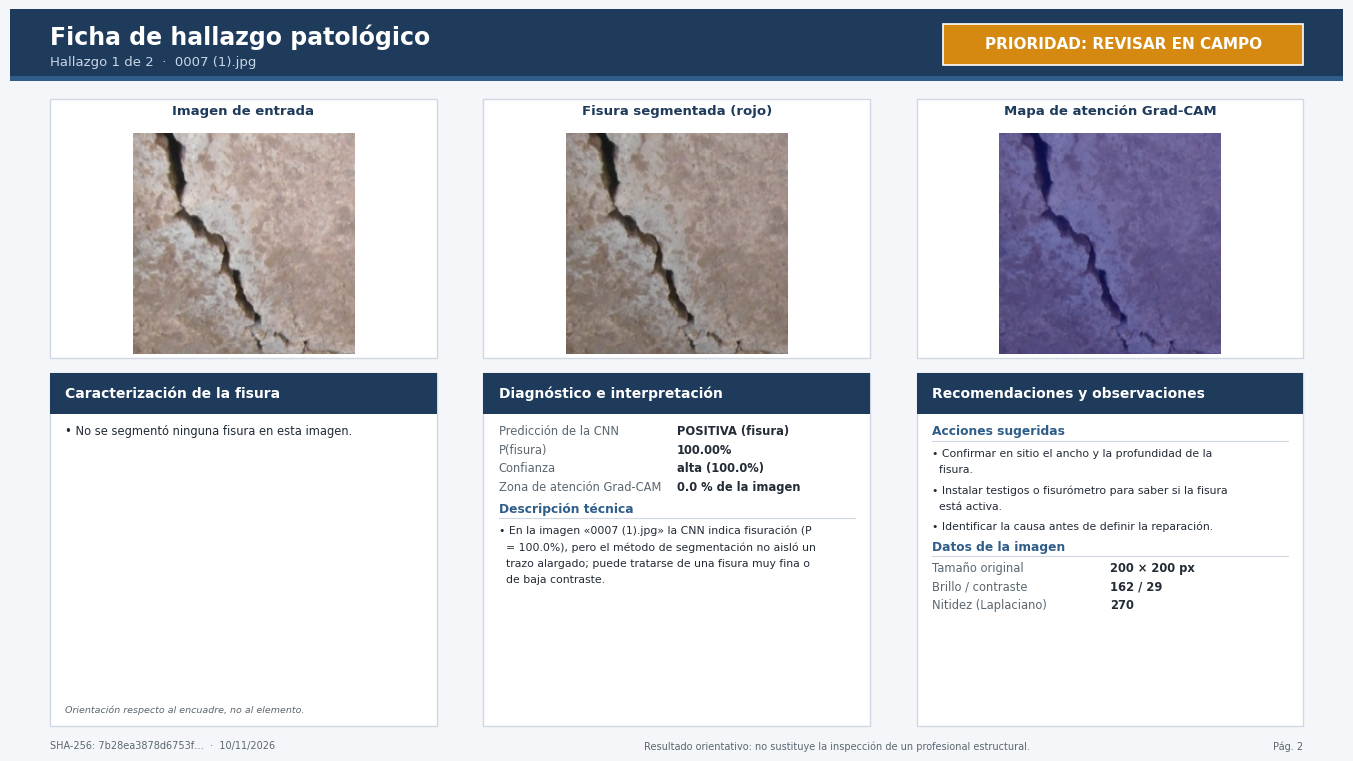

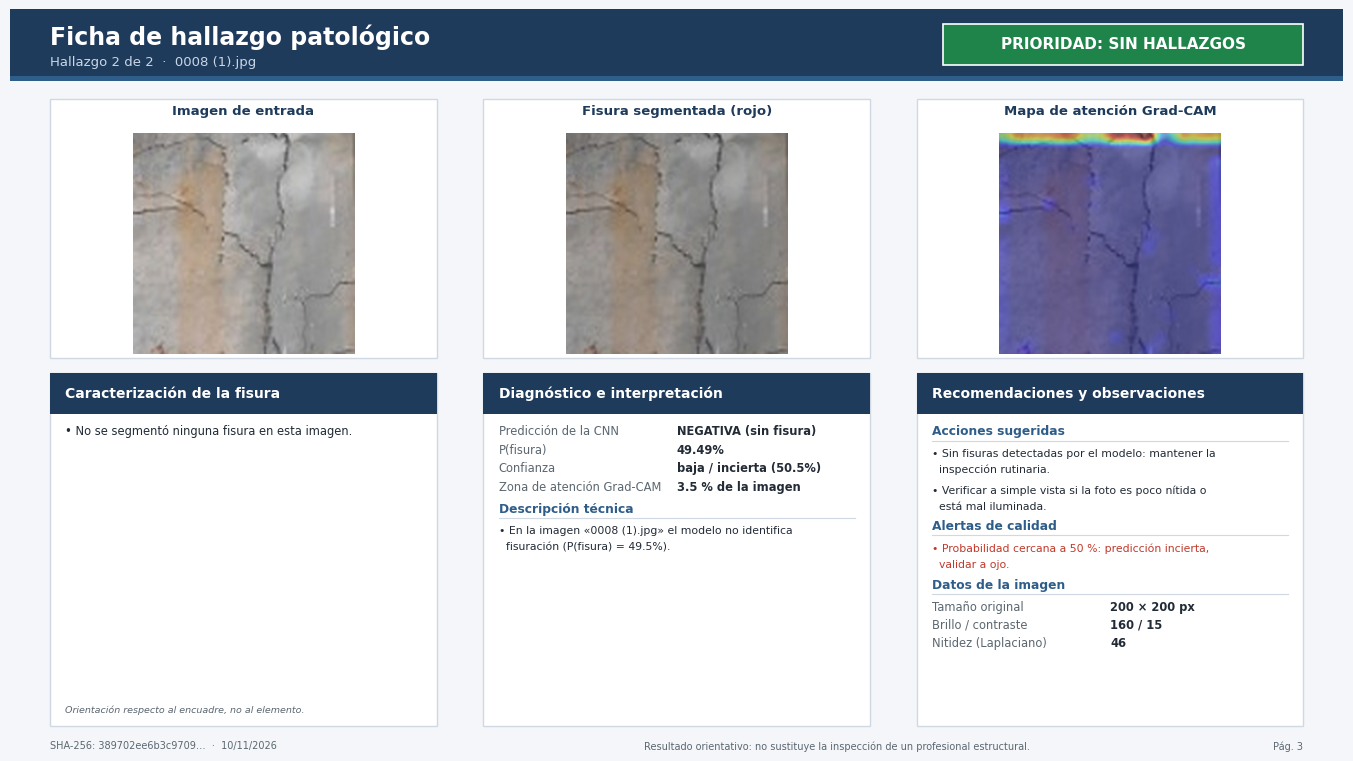

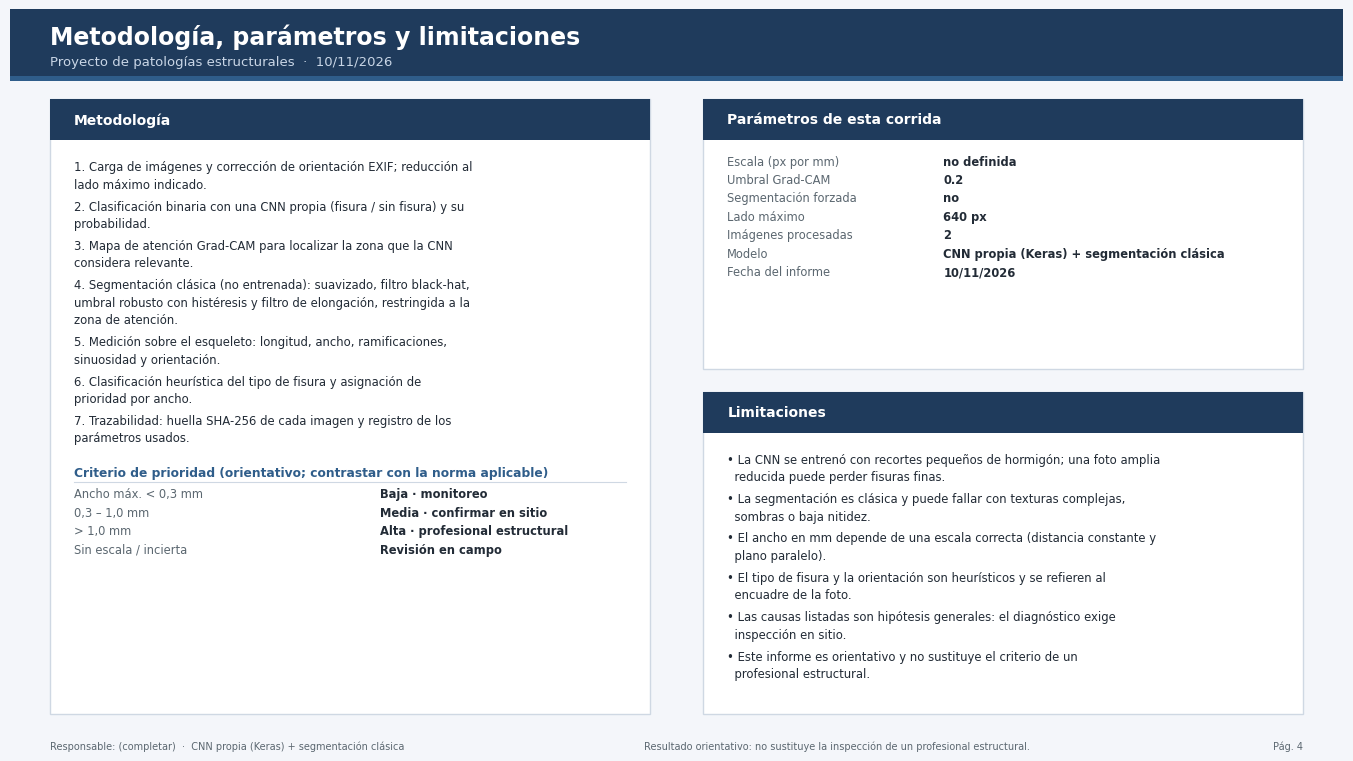

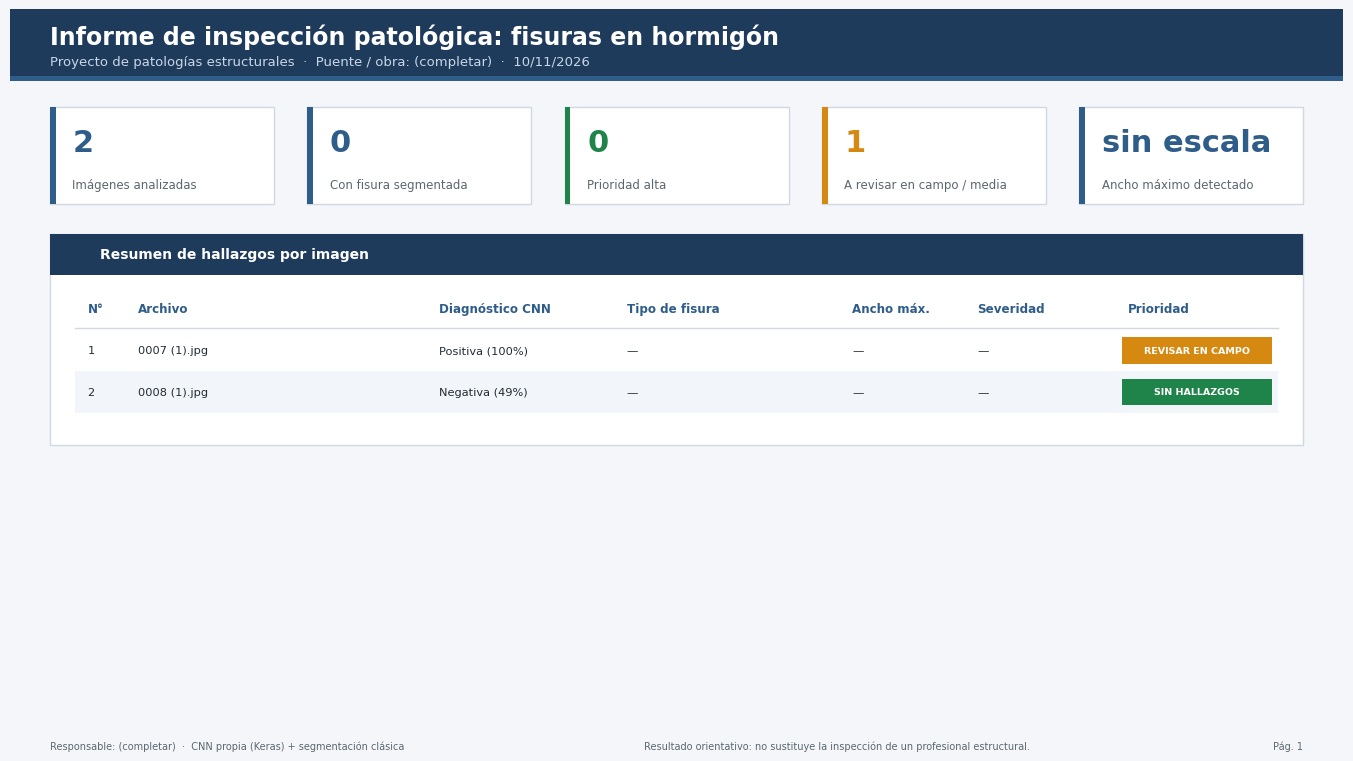

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

Informe PDF: /content/outputs/external_segmentation/informe_patologico.pdf

Resumen de los datos de reconocimiento:


,Predicción,P(Positive) %,Confianza,Tipo de grieta,Área grieta %,Longitud px,Ancho medio px,Ancho máx px,Segmentos,Ramificaciones,Ubicación,Límite ACI (mm),Evaluación ACI 224R,Elemento,Ubicación en la obra,Prioridad,Orientación,Sinuosidad,Ancho medio mm,Ancho máx mm
Archivo,,,,,,,,,,,,,,,,,,,,
0007 (1).jpg,Positive (grieta),100.00,alta,—,0.0,0,0.0,0.0,0,0,—,None,—,,,REVISAR EN CAMPO,—,None,None,None
0008 (1).jpg,Negative (sin grieta),49.49,baja / incierta,—,0.0,0,0.0,0.0,0,0,—,None,—,,,SIN HALLAZGOS,—,None,None,None


Archivos guardados en: /content/outputs/external_segmentation


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
# 12C. Subir imagen(es) -> informe patológico (PDF 16:9 + Excel) y archivos de salida
import shutil
from google.colab import files
from IPython.display import display

# ---------- Parámetros del análisis ----------
PX_POR_MM = None             # Ej.: 8.0 si 8 píxeles equivalen a 1 mm. None = sin escala (ancho solo en px)
UMBRAL_GRADCAM = 0.20        # Zona donde se busca la grieta (0 = toda la imagen; más alto = más restrictivo)
FORZAR_SEGMENTACION = False  # True = segmenta aunque la CNN prediga Negative
MAX_LADO = 640               # Lado máximo (px) para mostrar y segmentar

# ---------- Datos del informe ----------
PROYECTO = "Proyecto de patologías estructurales"
TITULO = "Informe de inspección patológica: fisuras en hormigón"
OBRA = "Puente / obra: (completar)"
INSPECTOR = "Responsable: (completar)"
MODELO = "CNN propia (Keras) + segmentación clásica"
MOSTRAR_MATRIZ = False       # True = además muestra la matriz Entrada | Segmentada | Datos
# Opcional: identificar cada foto dentro de la estructura (aparece en la ficha y en el Excel)
DATOS_POR_IMAGEN = {
    # "foto1.jpg": {"elemento": "Viga V2", "ubicacion": "Vano 3, cara inferior"},
}
# ----------------------------------------------

print("Selecciona una o varias imágenes de hormigón desde tu ordenador.")
subidas = files.upload()

extensiones_validas = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
resultados = []
for nombre, contenido in subidas.items():
    if not nombre.lower().endswith(extensiones_validas):
        print(f"Omitido (formato no compatible): {nombre}")
        continue
    try:
        resultados.append(
            analizar_imagen(
                nombre, contenido,
                px_por_mm=PX_POR_MM,
                max_lado=MAX_LADO,
                umbral_gradcam=UMBRAL_GRADCAM,
                forzar_segmentacion=FORZAR_SEGMENTACION,
            )
        )
    except Exception as e:
        print(f"No se pudo procesar {nombre}: {e}")

if not resultados:
    print("No hay imágenes válidas para analizar.")
else:
    carpeta_salida = Path(globals().get("output_dir", Path("outputs"))) / "external_segmentation"
    carpeta_salida.mkdir(parents=True, exist_ok=True)

    # Máscaras y superposiciones individuales
    for r in resultados:
        stem = Path(r["nombre"]).stem
        Image.fromarray((r["mascara"] * 255).astype(np.uint8)).save(carpeta_salida / f"{stem}_mascara.png")
        Image.fromarray(r["overlay"]).save(carpeta_salida / f"{stem}_segmentada.png")

    # Matriz visual clásica (opcional)
    if MOSTRAR_MATRIZ:
        dibujar_matriz(resultados, ruta_guardado=carpeta_salida / "matriz_resultados.png")

    # Informe patológico: PDF + PNG por página + Excel/CSV
    ruta_pdf, tabla = generar_informe(
        resultados, carpeta_salida,
        params=dict(px_por_mm=PX_POR_MM, umbral_gradcam=UMBRAL_GRADCAM,
                    forzar_segmentacion=FORZAR_SEGMENTACION, max_lado=MAX_LADO),
        titulo=TITULO, proyecto=PROYECTO, obra=OBRA, inspector=INSPECTOR,
        modelo=MODELO, datos_por_imagen=DATOS_POR_IMAGEN, mostrar=True,
    )

    print("\nResumen de los datos de reconocimiento:")
    display(tabla.drop(columns=["Causas probables", "Acciones sugeridas", "Alertas", "SHA-256"]))

    # Descarga: todo en un ZIP
    zip_path = shutil.make_archive(str(carpeta_salida.parent / "informe_patologico_completo"),
                                   "zip", carpeta_salida)
    print("Archivos guardados en:", carpeta_salida.resolve())
    files.download(zip_path)